# Modelagem: quanto a sua casa renderia no Airbnb

O usuário informa os atributos da casa, o endereço e (opcional) uma foto. O modelo devolve a diária, a
ocupação, a receita anual (com faixa), anúncios comparáveis e um mapa de "e se a sua casa estivesse em outro
distrito".

```
 atributos + amenities + lat/lon ──► [A] Diária (gradient boosting quantílico, log)
                                            │  ±
 foto ──► CLIP ──► [B] ajuste do resíduo ───┘
                                            ▼
 distrito, tipologia, perfil ──► [C] Ocupação (encolhimento) ──► [D] Receita = A × C (Monte Carlo)
                                                                       │
 IPTU (distrito × tipo, picos) × área, crime ──────────────────► [E] Yield e score por distrito
```

**Regra das features:** só entra o que o dono da casa sabe informar. Ficam de fora reviews, notas, histórico
do anfitrião e mínimo de noites (eles explicam o preço, mas não existem para uma casa nova).

**Por que não prever a receita direto:** a receita do Inside Airbnb é `preço × 2 × reviews_12m × max(3, min_nights)`
e 89% da variância dela vem da ocupação, isto é, das reviews (`eda_agregado` §7 e §18). Os atributos da casa
explicam a diária; a ocupação depende de demanda e do anfitrião. Por isso os dois são modelados separados.

Código reutilizável em `src/modelo.py` e `src/imagens.py`; o modelo treinado vai para `data/processed/modelo/`.

## lib

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src import modelo as M
from src import imagens as IMG

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
brl = lambda x: "R$ " + f"{x:,.0f}".replace(",", ".")
M.DIR_MODELO.mkdir(parents=True, exist_ok=True)

## 1. Dados

`price_ok` é o mesmo recorte do `eda_agregado` (§4.4): cotação de até 3 noites e sem outlier extremo de log-preço.

In [2]:
d = M.carregar_anuncios()
dp = d[d["price_ok"]].reset_index(drop=True)
X, CATS = M.montar_features(dp)
y, host = dp["log_price"].values, dp["host_id"].values
AMEN = M.amenity_cols(dp)
print(f"anúncios: {len(d):,} | com preço comparável (price_ok): {len(dp):,} | anfitriões: {dp['host_id'].nunique():,}")
print(f"amenities usadas como checklist: {len(AMEN)}")

anúncios: 42,354 | com preço comparável (price_ok): 38,033 | anfitriões: 13,559
amenities usadas como checklist: 50


## 2. [A] Diária

### 2.1 Quanto cada bloco de features acrescenta

Validação cruzada **agrupada por anfitrião** (5 dobras): nenhum anfitrião aparece no treino e no teste ao mesmo
tempo; a validação aleatória superestima o R² (`eda_agregado` §14). Alvo: log da diária. O ponto previsto é o
quantil 50%.

- **imóvel**: tipo de quarto, tipo de propriedade, capacidade, quartos, camas, banheiros, banheiro compartilhado
- **amenities**: as 40 mais frequentes + 10 "declaradas" verificáveis (piscina, academia, varanda…)
- **localização**: lat/lon e distância à Sé
- **vizinhança**: média do log-preço (ajustado por capacidade) dos 15 anúncios mais próximos de **outros** anfitriões
- **distrito**: IPTU, crime e POI do distrito (para conferir que, depois da localização, eles não acrescentam nada)

In [3]:
IMOVEL = ["room_type", "property_type", "accommodates", "bedrooms", "beds", "bathrooms", "bath_shared"]
AMENS = AMEN + ["n_amenities_top"]
LOCAL = ["latitude", "longitude", "dist_centro_km"]

# features distritais só para o teste do bloco (não entram no modelo final)
feat = pd.read_csv(M.PROC / "distrito_features.csv").set_index("distrito")
feat["crime_km2"] = feat["crime_total"] / feat["area_km2"]
feat["poi_km2"] = feat["poi_total"] / feat["area_km2"]
DIST = ["iptu_venal_m2_median", "iptu_share_apto", "crime_km2", "poi_km2"]
Xd = X.join(dp[["distrito"]]).join(feat[DIST], on="distrito").drop(columns="distrito")

blocos = [("imóvel", IMOVEL, False, X), ("+ amenities", IMOVEL + AMENS, False, X),
          ("+ localização", IMOVEL + AMENS + LOCAL, False, X), ("+ vizinhança", IMOVEL + AMENS + LOCAL, True, X),
          ("+ distrito (IPTU/crime/POI)", IMOVEL + AMENS + LOCAL + DIST, True, Xd)]
linhas = []
for nome, cols, viz, XX in blocos:
    p = M.prever_oof(XX, y, host, cols, usar_vizinhanca=viz)
    linhas.append({"bloco": nome, "n features": len(cols) + 2 * viz, **M.metricas(y, p)})
    if nome == "+ vizinhança":
        oof = p   # é o modelo final; guardamos as previsões fora da amostra
ablacao = pd.DataFrame(linhas).set_index("bloco")
ablacao.round(3)

,n features,R² (log),erro % mediano,cobertura 80%,largura mediana (×)
bloco,,,,,
imóvel,7,0.353,21.963,78.637,2.211
+ amenities,58,0.437,20.334,74.346,2.041
+ localização,61,0.529,18.425,72.292,1.834
+ vizinhança,63,0.535,18.100,72.950,1.827
+ distrito (IPTU/crime/POI),67,0.535,18.158,73.121,1.829


**Leitura**
- Sem nenhuma informação de review ou anfitrião, o modelo chega a R² ≈ 0,53 e erro mediano ≈ 18% — acima do
  0,50 do baseline do `eda_agregado` para imóvel + lat/lon.
- O bloco do distrito (IPTU, crime, POI) **não acrescenta** nada depois da localização, como o EDA já indicava:
  para a diária, a coordenada carrega a informação do distrito. Esses dados voltam no passo [E].
- A cobertura do intervalo q10–q90 fica abaixo de 80% antes da calibração (próxima célula).

### 2.2 Calibração do intervalo (conformal) e validação por distrito

O intervalo q10–q90 do gradient boosting costuma sair estreito demais. A **regressão quantílica conformal (CQR)**
mede, nas previsões fora da amostra, quanto o intervalo precisa ser alargado para cobrir 80% dos anúncios.

A validação **por distrito** é mais dura: prevê anúncios de distritos que o modelo nunca viu. Ela diz o que
esperar de uma casa num distrito com poucos anúncios.

In [4]:
COLS = IMOVEL + AMENS + LOCAL
cal = M.ModeloDiaria(COLS)
correcao = cal.calibrar(y, oof)
oof_cal = oof.copy()
oof_cal["q10"], oof_cal["q90"] = oof["q10"] - correcao, oof["q90"] + correcao
print(f"folga conformal: {correcao:+.3f} no log (×{np.exp(correcao):.2f} em cada ponta)")

from sklearn.model_selection import GroupKFold
pd_ = []
for tr, te in GroupKFold(5).split(X, y, dp["distrito"]):
    m = M.ModeloDiaria(COLS).fit(X.iloc[tr], y[tr], host[tr])
    m.correcao = correcao
    pd_.append(m.predict(X.iloc[te]))
oof_dist = pd.concat(pd_).loc[X.index]

pd.DataFrame({"CV por anfitrião (sem calibrar)": M.metricas(y, oof),
              "CV por anfitrião (calibrado)": M.metricas(y, oof_cal),
              "CV por distrito (calibrado)": M.metricas(y, oof_dist)}).T.round(3)

folga conformal: +0.054 no log (×1.06 em cada ponta)


,R² (log),erro % mediano,cobertura 80%,largura mediana (×)
CV por anfitrião (sem calibrar),0.535,18.100,72.950,1.827
CV por anfitrião (calibrado),0.535,18.100,80.004,2.035
CV por distrito (calibrado),0.405,21.036,83.995,2.454


### 2.3 Onde o modelo erra mais

Erro percentual mediano e cobertura por perfil e por região.

In [5]:
res = dp[["room_type", "accommodates", "regiao5", "distrito"]].copy()
res["perfil"] = M.perfil(dp["room_type"], dp["accommodates"]).values
res["erro_%"] = 100 * np.abs(np.expm1(oof_cal["q50"] - y))
res["coberto"] = (y >= oof_cal["q10"]) & (y <= oof_cal["q90"])
res["resid"] = y - oof_cal["q50"]
tab = lambda k: res.groupby(k).agg(n=("erro_%", "size"), erro_mediano=("erro_%", "median"),
                                   cobertura=("coberto", "mean"), vies=("resid", "median")).round(2)
display(tab("perfil"))
display(tab("regiao5"))

,n,erro_mediano,cobertura,vies
perfil,,,,
inteiro 1-2,17931,16.39,0.81,-0.01
inteiro 3-4,11776,17.34,0.81,-0.01
inteiro 5+,3191,22.73,0.77,0.01
quarto 1-2,4006,24.38,0.77,-0.02
quarto 3-4,862,27.59,0.74,0.01
quarto 5+,267,44.20,0.61,-0.05


,n,erro_mediano,cobertura,vies
regiao5,,,,
Centro,9281,18.82,0.81,-0.01
Leste,2704,19.45,0.78,-0.01
Norte,1411,22.62,0.72,-0.02
Oeste,13638,17.35,0.81,0.00
Sul,10999,17.76,0.80,-0.01


### 2.4 Sobrou estrutura espacial no erro? (Moran's I)

Pesos: 8 vizinhos mais próximos, padronizados por linha; significância por 199 permutações. Se o resíduo ainda
tiver autocorrelação forte, a localização não foi totalmente capturada. Comparamos com o Moran do próprio
log-preço e do resíduo de um modelo **sem** localização.

In [6]:
sem_loc = M.prever_oof(X, y, host, IMOVEL + AMENS, usar_vizinhanca=False)
lat, lon = dp["latitude"].values, dp["longitude"].values
moran = pd.DataFrame({
    "log-preço": M.moran_knn(y, lat, lon),
    "resíduo sem localização": M.moran_knn(y - sem_loc["q50"], lat, lon),
    "resíduo do modelo final": M.moran_knn(y - oof_cal["q50"], lat, lon),
}).T
moran.round(4)

,I,p_sim,E[I]
log-preço,0.3558,0.005,-0.0
resíduo sem localização,0.2906,0.005,-0.0
resíduo do modelo final,0.1158,0.005,-0.0


**Leitura**
- O Moran do resíduo cai bastante em relação ao do log-preço e ao do modelo sem localização: lat/lon e a vizinhança
  capturam a maior parte da estrutura espacial do preço.
- O que sobra é pequeno, mas significativo com ~38 mil pontos: parte é o próprio prédio (anúncios do mesmo
  anfitrião lado a lado), que nenhuma feature do usuário captura.

### 2.5 Treino final (todos os anúncios com preço comparável)

In [7]:
modelo_A = M.ModeloDiaria(COLS).fit(X, y, host)
modelo_A.correcao = correcao
print("features:", len(modelo_A.feature_names))

features: 63


## 3. [B] Foto de capa

Amostra aleatória de 6 mil anúncios com preço comparável; a capa é baixada reduzida (480 px, ~25 KB) pelo
redimensionador do CDN do Airbnb e vira um vetor CLIP (`openai/clip-vit-base-patch32`, o mesmo dos notebooks de
`imageAnalysis`).

A foto **não** entra no modelo [A]. Ela prevê o **resíduo** de [A] (fora da amostra): o quanto o anúncio é mais
caro ou mais barato do que os atributos e a localização explicam. Assim a foto só pode acrescentar informação, e o
ajuste é encolhido pelo quanto ela realmente acerta.

No `clusters_amostra.ipynb` (200 anúncios) a capa explicava R² ≈ 0,08 do preço ajustado por tipo e capacidade.
Aqui o teste é mais duro: o resíduo já desconta amenities e localização.

In [8]:
amostra = d[d["price_ok"] & d["picture_url"].notna()].sample(6000, random_state=42)
rel = IMG.baixar_amostra(amostra)          # idempotente: só baixa o que falta
print(rel["status"].value_counts().to_dict())
ids_foto, emb = IMG.embeddings_amostra(amostra["id"])
print("embeddings:", emb.shape)

pos = pd.Series(np.arange(len(dp)), index=dp["id"])
idx = pos[ids_foto].values
resid = y[idx] - oof_cal["q50"].values[idx]
grupos = host[idx]

{'existente': 5599, 'falhou': 401}
embeddings: (5599, 512)


In [9]:
B = M.AjusteFoto()
p_oof = B.oof(emb, resid, grupos)
from sklearn.metrics import r2_score
B.fit(emb, resid, grupos)
aj = B.fator * p_oof          # ajuste fora da amostra, já encolhido

erroA = np.abs(np.expm1(-resid))
erroAB = np.abs(np.expm1(aj - resid))
print(f"R² do resíduo de [A] explicado pela foto (fora da amostra): {r2_score(resid, p_oof):.3f}")
print(f"Spearman(previsto, resíduo real): {spearmanr(p_oof, resid)[0]:.3f} | fator de encolhimento: {B.fator:.2f}")
print(f"erro % mediano  só [A]: {100 * np.median(erroA):.1f}%  |  [A] + foto: {100 * np.median(erroAB):.1f}%")
print(f"ajuste típico da foto (p10–p90): {100 * np.expm1(np.percentile(aj, 10)):+.0f}% a {100 * np.expm1(np.percentile(aj, 90)):+.0f}%")

R² do resíduo de [A] explicado pela foto (fora da amostra): 0.033
Spearman(previsto, resíduo real): 0.178 | fator de encolhimento: 1.00
erro % mediano  só [A]: 18.2%  |  [A] + foto: 18.7%
ajuste típico da foto (p10–p90): -6% a +9%


**Leitura**
- A foto explica pouco do que sobra depois de [A]: R² ≈ 0,03 do resíduo e Spearman ≈ 0,18 fora da amostra. O sinal
  existe (ela ordena um pouco quem está acima ou abaixo do esperado), mas é fraco.
- O erro mediano **não melhora** (≈ 18,2% → 18,7%): o ajuste ganha nos anúncios muito fora do esperado (o R² é
  positivo) e perde um pouco nos típicos. Boa parte do que a capa mostrava no `clusters_amostra` (piscina, padrão do
  prédio) já entra pelas amenities e pela localização.
- **Uso no produto:** a foto fica como **explicação** (conceitos visuais) e para achar **comparáveis parecidos**; o
  ajuste de preço é mostrado à parte, como "a sua foto sugere ±x%", e não muda a faixa principal.

### 3.1 O que na foto se associa ao resíduo

Os mesmos eixos zero-shot de `clip_prompts.json` (limpeza, espaço, luz, decoração, vista, lazer): margem entre os
protótipos positivos e negativos, padronizada na amostra. Spearman com o resíduo de [A], com Benjamini-Hochberg.
Associação, não causa.

In [10]:
from scipy.stats import false_discovery_control
eixos = IMG.eixos_conceitos()
sc = emb @ eixos.values.T
conc_media, conc_dp = sc.mean(0), sc.std(0)
z = (sc - conc_media) / conc_dp
linhas = []
for j, nome in enumerate(eixos.index):
    r_, p_ = spearmanr(z[:, j], resid)
    linhas.append({"aspecto": nome, "rho": r_, "p": p_,
                   "prêmio por +1 dp (%)": 100 * np.expm1(np.polyfit(z[:, j], resid, 1)[0])})
conc = pd.DataFrame(linhas)
conc["p_bh"] = false_discovery_control(conc["p"])
conc.sort_values("rho", ascending=False).round(3)

,aspecto,rho,p,prêmio por +1 dp (%),p_bh
3,decor,0.115,0.000,3.101,0.000
2,light,0.112,0.000,3.404,0.000
5,leisure,0.076,0.000,1.246,0.000
1,space,0.075,0.000,2.119,0.000
4,view,0.063,0.000,1.300,0.000
0,cleanliness,-0.038,0.004,-1.111,0.004


## 4. [C] Ocupação

A ocupação **não** é prevista pelos atributos: ela vem das reviews (e não existe para uma casa nova). O que o
modelo entrega é a **distribuição** da ocupação de anúncios parecidos (mesmo perfil) no mesmo distrito.

- **Base:** anúncios **maduros** (1ª avaliação há pelo menos 12 meses; senão a janela de 365 dias está truncada
  — mais da metade do mercado entrou em 2025–26) e **em operação** (≥ 1 avaliação em 12 meses).
- **Perfil:** casa/apto inteiro × quarto, e capacidade 1–2 / 3–4 / 5+.
- **Encolhimento:** distritos com poucos anúncios herdam a **tipologia** urbana (k-means sobre IPTU, crime, POI,
  área e distância à Sé — sem nenhuma métrica dos anúncios, como no `eda_agregado` §22), e a tipologia herda o
  perfil na cidade: `q = (n·q_distrito + 15·q_grupo) / (n + 15)`.
- **`p_inativo`:** fração dos anúncios maduros **sem nenhuma** avaliação em 12 meses. É o risco de o anúncio não
  "pegar"; fica fora da receita (que é condicional a operar) e aparece ao lado dela.

In [11]:
g = gpd.read_file(M.EXT / "distrito_municipal.geojson")
g["distrito"] = g["nm_distrito_municipal"].map(M.chave)
rp = g.to_crs(31983).representative_point().to_crs(4326)
g["lat"], g["lon"] = rp.y.values, rp.x.values
g = g.set_index("distrito")

feat["dist_centro_km"] = M.haversine_km(g.loc[feat.index, "lat"], g.loc[feat.index, "lon"], *M.CENTRO)
Z = pd.DataFrame({"iptu": np.log(feat["iptu_venal_m2_median"]), "crime_km2": np.log1p(feat["crime_km2"]),
                  "poi_km2": np.log1p(feat["poi_km2"]), "area": np.log(feat["area_km2"]),
                  "dist": feat["dist_centro_km"], "apto": feat["iptu_share_apto"]})
Zs = StandardScaler().fit_transform(Z)
pca = PCA(3, random_state=42).fit(Zs)
grupo = KMeans(4, n_init=20, random_state=42).fit_predict(pca.transform(Zs))
ordem = feat.groupby(grupo)["dist_centro_km"].mean().sort_values().index      # T1 = mais central
tipologia = pd.Series([f"T{list(ordem).index(c) + 1}" for c in grupo], index=feat.index, name="tipologia")
print("variância explicada pelo PCA:", pca.explained_variance_ratio_.round(2))
print(tipologia.value_counts().sort_index().to_dict())

ocupacao = M.tabela_ocupacao(d, tipologia)
print(ocupacao.shape)
ocupacao.loc[["REPUBLICA", "ITAIM BIBI", "TATUAPE", "PARELHEIROS"]].round(2)

variância explicada pelo PCA: [0.74 0.11 0.09]
{'T1': 17, 'T2': 46, 'T3': 30, 'T4': 3}
(576, 9)


tipologia  n_distrito  n_tipologia    p10    p25     p50     p75     p90  p_inativo
distrito    perfil                                                                                         
REPUBLICA   inteiro 1-2        T1        1177         6638  23.92  53.85  135.50  254.13  255.00       0.11
            inteiro 3-4        T1         620         4925  18.00  48.00  128.50  227.29  255.00       0.10
            inteiro 5+         T1         119         1110  12.87  30.67   93.99  193.09  255.00       0.15
            quarto 1-2         T1          89         1056   6.86  23.99   71.98  157.69  255.00       0.34
            quarto 3-4         T1          14          188   9.57  24.52   61.01  126.31  204.89       0.20
            quarto 5+          T1           1           42   8.12  13.75   34.38   87.32  240.17       0.22
ITAIM BIBI  inteiro 1-2        T1         824         6638  12.11  30.21   71.45  150.64  228.48       0.13
            inteiro 3-4        T1         733         4925  18.00  36.24  102.12  186.24  255.00       0.11
            inteiro 5+         T1         120         1110  28.33  62.64  109.96  183.30  255.00       0.10
            quarto 1-2         T1         201         1056  10.13  24.00   66.40  173.57  246.62       0.20
            quarto 3-4         T1          21          188  10.04  28.50   99.32  216.67  255.00       0.23
            quarto 5+          T1           2           42  10.84  20.21   46.41  103.04  250.97       0.21
TATUAPE     inteiro 1-2        T2          85         1887  23.10  36.90   90.90  161.39  214.71       0.11
            inteiro 3-4        T2          33         1430  10.58  58.52  104.27  145.18  226.54       0.05
            inteiro 5+         T2          15          564   9.05  25.66   60.39  101.04  155.75       0.12
            quarto 1-2         T2          15          751   6.02  12.02   36.12   97.79  237.75       0.34
            quarto 3-4         T2           2          164   9.59  20.12   47.29  112.86  202.94       0.25
            quarto 5+          T2           0           51   6.00  16.64   44.82  121.50  237.68       0.19
PARELHEIROS inteiro 1-2        T4           2            3  16.31  36.18   79.59  149.03  201.72       0.08
            inteiro 3-4        T4           4            4  25.01  50.83   92.96  154.14  194.42       0.19
            inteiro 5+         T4          11           25   8.16  18.49   59.68  106.07  157.05       0.32
            quarto 1-2         T4           0            1  21.75  33.00   70.50  154.88  253.31       0.32
            quarto 3-4         T4           0            0   6.00  18.00   48.00  138.00  255.00       0.24
            quarto 5+          T4           0            0   6.00  12.00   34.00   96.00  250.20       0.20

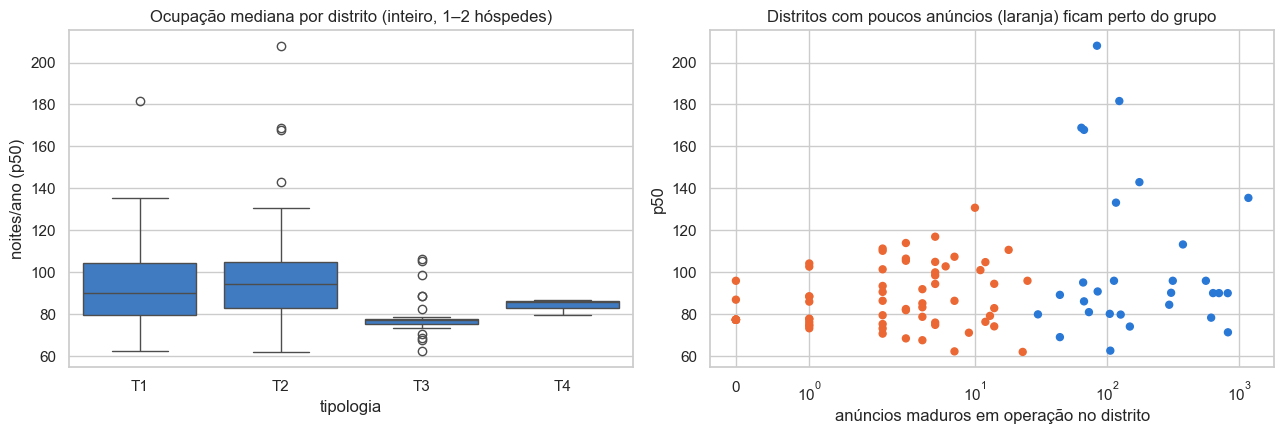

In [12]:
# ocupação mediana (inteiro 1–2 hóspedes) por tipologia, antes e depois de encolher
v = ocupacao.xs("inteiro 1-2", level="perfil").join(feat[["regiao5"]])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=v.reset_index(), x="tipologia", y="p50", order=["T1", "T2", "T3", "T4"], color=AZUL, ax=ax[0])
ax[0].set(title="Ocupação mediana por distrito (inteiro, 1–2 hóspedes)", ylabel="noites/ano (p50)")
ax[1].scatter(v["n_distrito"], v["p50"], c=[LARANJA if n < 30 else AZUL for n in v["n_distrito"]], s=25)
ax[1].set_xscale("symlog"); ax[1].set(title="Distritos com poucos anúncios (laranja) ficam perto do grupo",
                                      xlabel="anúncios maduros em operação no distrito", ylabel="p50")
plt.tight_layout(); plt.show()

## 5. [D] Receita = diária × ocupação

Monte Carlo: a diária é sorteada da distribuição de [A] (normal assimétrica no log, pelos quantis calibrados) e a
ocupação da distribuição de [C] (interpolação entre os quantis). Os dois são sorteados **independentes**: entre
distritos, preço e ocupação têm ρ = +0,09 (`eda_agregado` §18).

**Validação:** para os anúncios maduros e em operação, usamos a diária prevista **fora da amostra** e a ocupação do
distrito × perfil, e conferimos se a receita estimada pelo Inside Airbnb cai dentro da faixa p10–p90 em ~80% das vezes.
(A tabela de ocupação inclui o próprio anúncio; com o encolhimento, o efeito é pequeno nos distritos grandes.)

anúncios validados: 17,493
cobertura p10–p90: 85.2% (alvo 80%)
receita real abaixo da mediana prevista: 50.8% (alvo 50%)
Spearman(receita mediana prevista, real): 0.399


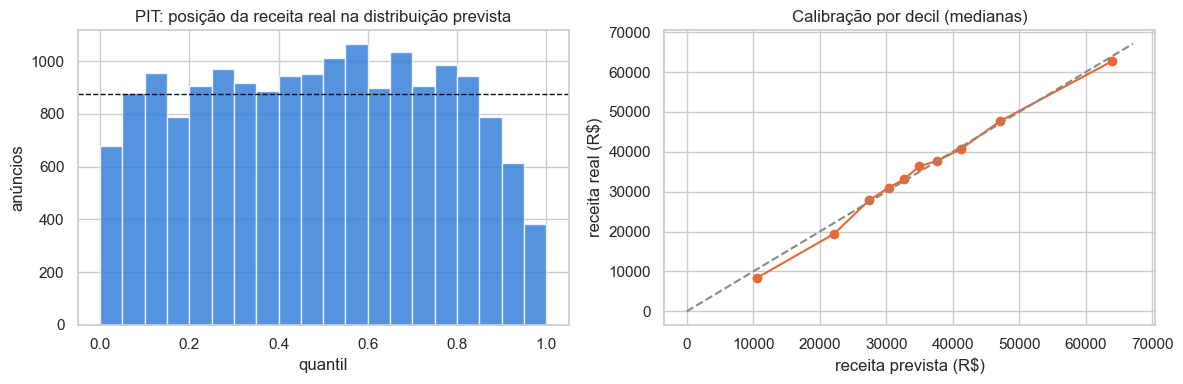

In [13]:
QC = [f"p{int(q * 100)}" for q in M.Q_OCUP]
val = dp.assign(perfil=M.perfil(dp["room_type"], dp["accommodates"]).values)
maduro = (val["first_review"] <= val["last_scraped"] - pd.Timedelta(days=365)) & (val["number_of_reviews_ltm"] > 0)
iv = np.where(maduro.values)[0]
rng = np.random.default_rng(42)
N = 400
lp = np.column_stack([M.amostrar_log_preco(a, b, c, N, rng) for a, b, c in
                      oof_cal[["q10", "q50", "q90"]].values[iv]]).T
qq = ocupacao.loc[list(zip(val["distrito"].values[iv], val["perfil"].values[iv])), QC].values
noites = np.vstack([M.amostrar_ocupacao(q, N, rng) for q in qq])
rec = np.exp(lp) * noites
real = val["estimated_revenue_l365d"].values[iv]
p10, p50, p90 = np.percentile(rec, [10, 50, 90], axis=1)
pit = (rec < real[:, None]).mean(1)
print(f"anúncios validados: {len(iv):,}")
print(f"cobertura p10–p90: {100 * np.mean((real >= p10) & (real <= p90)):.1f}% (alvo 80%)")
print(f"receita real abaixo da mediana prevista: {100 * np.mean(real < p50):.1f}% (alvo 50%)")
print(f"Spearman(receita mediana prevista, real): {spearmanr(p50, real)[0]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pit, bins=20, color=AZUL, alpha=0.8); ax[0].axhline(len(pit) / 20, color="#0b0b0b", ls="--", lw=1)
ax[0].set(title="PIT: posição da receita real na distribuição prevista", xlabel="quantil", ylabel="anúncios")
dec = pd.qcut(p50, 10, labels=False)
cal_ = pd.DataFrame({"prev": p50, "real": real, "dec": dec}).groupby("dec").median()
ax[1].plot(cal_["prev"], cal_["real"], "o-", color=LARANJA); lim = [0, cal_.max().max() * 1.05]
ax[1].plot(lim, lim, color=CINZA, ls="--"); ax[1].set(title="Calibração por decil (medianas)",
                                                       xlabel="receita prevista (R$)", ylabel="receita real (R$)")
plt.tight_layout(); plt.show()

**Como ler:** um PIT plano significa que a faixa está calibrada; forma de U significa faixa estreita demais, e
forma de sino, larga demais. A ordenação (Spearman) é modesta por construção: a ocupação de um anúncio individual
depende do anfitrião, e o modelo só conhece o distrito e o perfil — é por isso que o produto mostra **faixa**, não
um número.

## 6. [E] Investimento

### 6.1 Custo: valor venal/m² por distrito × tipo e os picos

O custo é `venal/m² × fator venal→mercado × área`, com o venal/m² **mediano do distrito para o tipo da casa**
(apartamento × casa).

**Hipótese dos picos:** nos 20 distritos com venal/m² bimodal, os dois picos seriam casa × apartamento? A tabela
mostra a fração de apartamentos abaixo e acima do ponto médio entre os picos.

In [14]:
iptu = M.carregar_iptu()
venal_tipo = iptu.groupby(["distrito", "tipo"])["venal_m2"].median()
n_tipo = iptu.groupby(["distrito", "tipo"]).size()
VENAL = venal_tipo[n_tipo >= 30].to_dict()        # mediana só com amostra mínima

pk1 = pd.read_csv(M.PROC / "distrito_crime_iptu_receita_pico1.csv").set_index("distrito")
pk2 = pd.read_csv(M.PROC / "distrito_crime_iptu_receita_pico2.csv").set_index("distrito")["iptu_venal_m2"]
multi = pk1.index[pk1["iptu_multimodal"]]
linhas = []
for dn in multi:
    corte = np.sqrt(pk1.at[dn, "iptu_venal_m2"] * pk2[dn])
    x = iptu[iptu["distrito"] == dn]
    linhas.append({"distrito": dn, "pico1": pk1.at[dn, "iptu_venal_m2"], "pico2": pk2[dn],
                   "% apto abaixo": (x.loc[x["venal_m2"] < corte, "tipo"] == "apartamento").mean(),
                   "% apto acima": (x.loc[x["venal_m2"] >= corte, "tipo"] == "apartamento").mean(),
                   "mediana apto": VENAL.get((dn, "apartamento")), "mediana casa": VENAL.get((dn, "casa"))})
picos = pd.DataFrame(linhas).set_index("distrito")
picos["separa tipo?"] = (picos["% apto abaixo"] - picos["% apto acima"]) > 0.4
picos.round(2)

,pico1,pico2,% apto abaixo,% apto acima,mediana apto,mediana casa,separa tipo?
distrito,,,,,,,
ALTO DE PINHEIROS,4050.08,5357.50,0.83,0.24,3457.20,5780.29,True
ARTUR ALVIM,1226.76,2549.91,0.88,0.22,1292.61,2459.66,True
BARRA FUNDA,2779.13,3598.00,0.99,0.89,2845.63,4445.81,False
BELA VISTA,2719.96,4138.19,1.00,0.94,2795.66,6079.89,False
BOM RETIRO,1418.56,2705.37,0.86,0.70,2160.75,2506.60,False
CAMBUCI,2854.90,3617.41,0.84,0.70,2846.73,3477.12,False
CANGAIBA,2045.17,2509.09,0.35,0.25,2033.12,2189.21,False
CONSOLACAO,2549.91,4050.08,1.00,0.92,3023.76,6612.85,False
CURSINO,2468.91,3409.54,0.62,0.40,2687.73,3387.83,False


**Leitura**
- Em poucos distritos (Alto de Pinheiros, Artur Alvim) os picos separam apartamento de casa; nos centrais
  (Sé, República, Consolação, Bela Vista, Jardim Paulista, Santa Cecília) **os dois picos são de apartamentos**
  (> 90% dos dois lados): são dois padrões de prédio, não dois tipos de imóvel.
- Por isso o custo usa a mediana **por tipo**, e, para apartamento num distrito bimodal, o simulador mostra também a
  **faixa** entre o pico baixo e o alto (prédio mais simples × mais caro).

### 6.2 Fator venal → mercado e risco

O venal do IPTU fica bem abaixo do preço de mercado. Sem preço de transação por imóvel, usamos um fator único: a
razão entre o preço médio de venda em São Paulo (FipeZAP) e a mediana do venal/m² residencial. **O valor do FipeZAP
abaixo é aproximado e precisa ser confirmado.** Ele muda o nível do yield, mas não a ordem dos distritos.

Risco: crime violento por mil imóveis residenciais do IPTU (aproxima a população residente; a população do IBGE
ainda não está em `data/external`). Nos 25 distritos sem DP, a **taxa** é herdada do distrito de onde a contagem veio
(regra do `05 - Methodology`, 2026-11-03). Lembrete: no centro a população flutuante infla a taxa.

In [15]:
FIPEZAP_SP_M2 = 11_500                     # R$/m², venda, município de SP — APROXIMADO, CONFIRMAR
FATOR = FIPEZAP_SP_M2 / iptu["venal_m2"].median()
print(f"mediana venal/m²: {brl(iptu['venal_m2'].median())} → fator venal→mercado ≈ {FATOR:.2f}")

crime = feat["crime_violento"] / feat["iptu_n"] * 1000
for dn in feat.index[feat["crime_source"] == "nearest-imputed"]:
    fonte = feat[(feat["crime_source"] == "dp-direct") & (feat["crime_total"] == feat.at[dn, "crime_total"])
                 & (feat["crime_violento"] == feat.at[dn, "crime_violento"])].index
    crime[dn] = crime[fonte].mean()
print("crime violento por mil imóveis:", crime.describe(percentiles=[.25, .5, .75]).round(1).to_dict())

mediana venal/m²: R$ 2.486 → fator venal→mercado ≈ 4.63
crime violento por mil imóveis: {'count': 96.0, 'mean': 490.1, 'std': 965.6, 'min': 24.3, '25%': 72.5, '50%': 144.2, '75%': 467.9, 'max': 4554.8}


### 6.3 Montar o simulador

In [16]:
coord = dp.groupby("distrito")[["latitude", "longitude"]].median()
n_dist = dp.groupby("distrito").size()
centro = g[["lat", "lon"]].copy()
ok = n_dist[n_dist >= 10].index
centro.loc[ok, "lat"], centro.loc[ok, "lon"] = coord.loc[ok, "latitude"], coord.loc[ok, "longitude"]

bundle = {
    "modelo_A": modelo_A, "categorias": CATS, "amenities": AMEN,
    "modelo_B": B, "emb_ids": ids_foto, "emb": emb,
    "eixos_conceitos": eixos, "conceitos_media": conc_media, "conceitos_dp": conc_dp,
    "ocupacao": ocupacao, "tipologia": tipologia,
    "venal": VENAL, "picos": {dn: (r["pico1"], r["pico2"]) for dn, r in picos.iterrows()},
    "fator_mercado": FATOR, "crime": crime.to_dict(),
    "centro_distrito": centro, "poligonos": g[["geometry"]],
    "base_comparaveis": dp[["id", "listing_url", "room_type", "latitude", "longitude", "distrito", "accommodates",
                            "bedrooms", "bathrooms", "price_num", "estimated_occupancy_l365d",
                            "estimated_revenue_l365d"]],
}
import joblib
joblib.dump(bundle, M.DIR_MODELO / "modelo.joblib", compress=3)
print("salvo:", (M.DIR_MODELO / "modelo.joblib").relative_to(ROOT))

salvo: data/processed/modelo/modelo.joblib


### 6.4 Score por distrito: "e se a sua casa estivesse em outro distrito?"

Uma casa de referência (apartamento inteiro, 2 hóspedes, 1 quarto, 1 banheiro, 45 m², Wi-Fi, cozinha,
ar-condicionado) avaliada nos 96 distritos. Para cada um: diária [A], ocupação [C], receita [D], custo e yield [E].

**Score** = 0,7 × percentil do yield + 0,3 × (1 − percentil do crime). Os pesos são uma escolha explícita; a
sensibilidade vem logo abaixo.

In [17]:
CASA_REF = {"room_type": "Entire home/apt", "property_type": "Entire rental unit", "accommodates": 2,
            "bedrooms": 1, "beds": 1, "bathrooms": 1, "area_m2": 45,
            "amenities": ["wifi", "kitchen", "air_conditioning", "tv", "hot_water", "essentials"]}
ranking = M.e_se_outro_distrito(CASA_REF, bundle)
ranking["tipologia"] = ranking.index.map(tipologia)

def score(r, w):
    return w * r["yield_%"].rank(pct=True) + (1 - w) * (1 - r["crime_violento_mil"].rank(pct=True))
ranking["score"] = score(ranking, 0.7)
ranking = ranking.sort_values("score", ascending=False)
fmt = {"diaria_p50": brl, "receita_p50": brl, "custo": brl}
ranking.head(15).style.format({**fmt, "ocupacao_p50": "{:.0f}", "p_inativo": "{:.0%}", "yield_%": "{:.1f}",
                               "crime_violento_mil": "{:.0f}", "score": "{:.2f}"})

,diaria_p50,ocupacao_p50,receita_p50,p_inativo,custo,yield_%,crime_violento_mil,tipologia,score
distrito,,,,,,,,,
MORUMBI,R$ 408,89,R$ 39.376,9%,R$ 543.270,7.2,28,T2,0.94
BELEM,R$ 280,168,R$ 42.364,2%,R$ 528.604,8.0,47,T2,0.93
ARTUR ALVIM,R$ 308,83,R$ 24.802,8%,R$ 269.049,9.2,79,T2,0.91
TUCURUVI,R$ 273,169,R$ 39.893,8%,R$ 505.085,7.9,73,T2,0.88
SANTANA,R$ 263,143,R$ 36.623,2%,R$ 553.273,6.6,53,T2,0.87
AGUA RASA,R$ 245,208,R$ 43.271,4%,R$ 519.471,8.3,134,T2,0.84
SE,R$ 237,182,R$ 40.658,5%,R$ 338.031,12.0,241,T1,0.82
SAPOPEMBA,R$ 205,111,R$ 24.053,9%,R$ 382.471,6.3,82,T2,0.81
REPUBLICA,R$ 269,135,R$ 35.994,11%,R$ 397.982,9.0,241,T1,0.81


In [18]:
# sensibilidade do ranking ao peso do yield
base_rank = ranking["score"].rank(ascending=False)
top_base = set(ranking.index[:15])
sens = []
for w in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    s = score(ranking, w)
    sens.append({"peso do yield": w, "Spearman com 0,7": spearmanr(s, ranking["score"], nan_policy="omit")[0],
                 "top-15 em comum": len(top_base & set(s.sort_values(ascending=False).index[:15]))})
pd.DataFrame(sens).round(3)

,peso do yield,"Spearman com 0,7",top-15 em comum
0,0.5,0.899,11
1,0.6,0.978,13
2,0.7,1.000,15
3,0.8,0.983,13
4,0.9,0.949,13
5,1.0,0.918,13


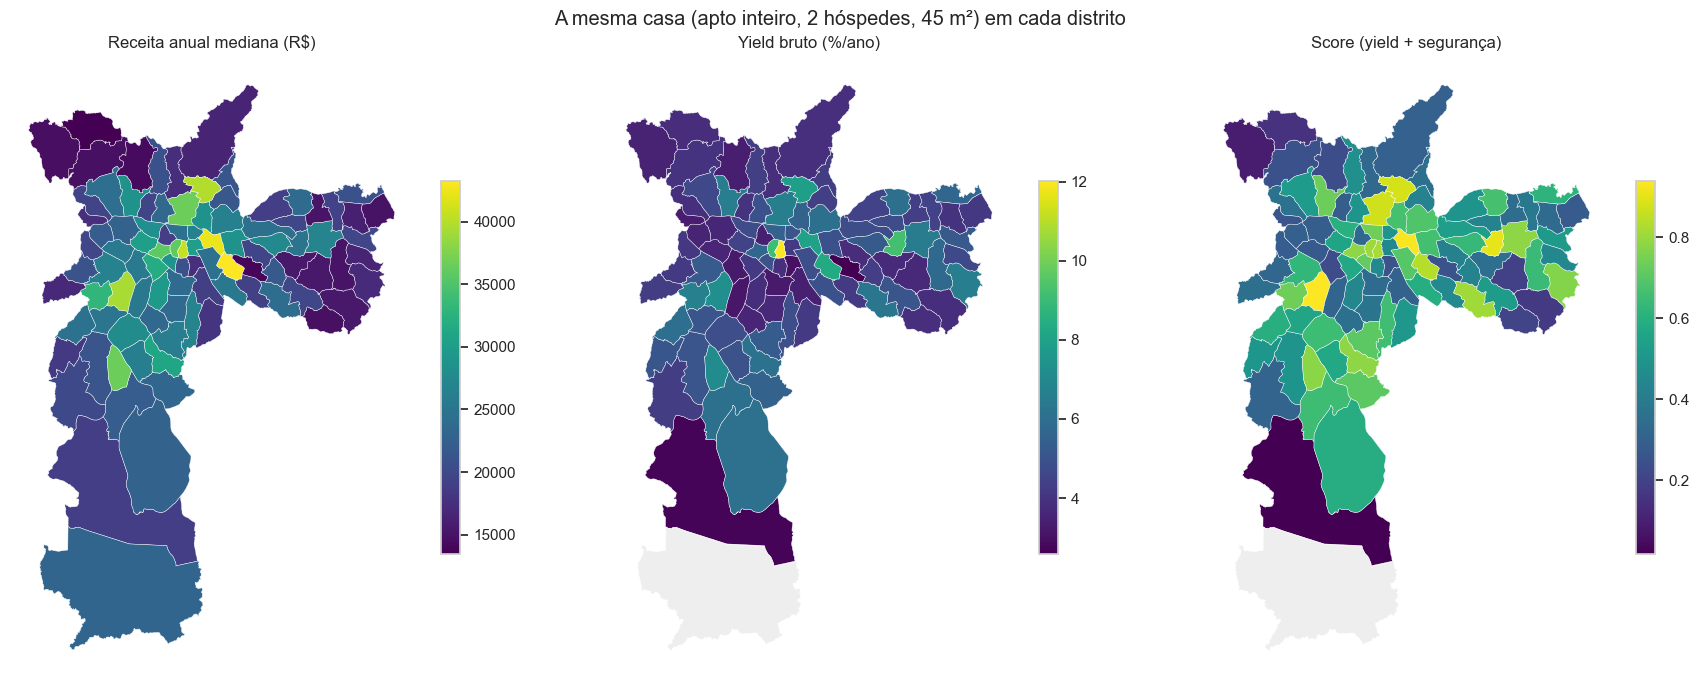

In [19]:
mapa = g.join(ranking[["yield_%", "receita_p50", "score"]])
fig, ax = plt.subplots(1, 3, figsize=(18, 7))
for a, col, tit in zip(ax, ["receita_p50", "yield_%", "score"],
                       ["Receita anual mediana (R$)", "Yield bruto (%/ano)", "Score (yield + segurança)"]):
    mapa.plot(column=col, cmap="viridis", legend=True, ax=a, edgecolor="white", linewidth=0.3,
              missing_kwds={"color": "#eeeeee"}, legend_kwds={"shrink": 0.6})
    a.set_title(tit); a.set_axis_off()
fig.suptitle("A mesma casa (apto inteiro, 2 hóspedes, 45 m²) em cada distrito", y=0.98)
plt.tight_layout(); plt.show()

## 7. Demo do simulador

Três casas de exemplo. A segunda usa a capa de um anúncio real da amostra no lugar da foto do usuário.

In [20]:
def mostrar(r):
    dia, rec = r["diaria"], r["receita_anual"]
    print(f"distrito: {r['distrito'].title()} | perfil: {r['perfil']} | tipo (IPTU): {r['tipo_iptu']}")
    print(f"  diária: {brl(dia['p50'])}  (faixa 80%: {brl(dia['p10'])} – {brl(dia['p90'])})"
          + (f"  | ajuste da foto: {dia['ajuste_foto_%']:+.1f}%" if dia["ajuste_foto_%"] else ""))
    oc = r["ocupacao_noites"]
    print(f"  ocupação (noites/ano): pessimista {oc['p25']:.0f} | típica {oc['p50']:.0f} | otimista {oc['p75']:.0f}"
          f"  | risco de não engrenar: {r['p_inativo']:.0%}")
    print(f"  receita anual: {brl(rec['p50'])}  (faixa 80%: {brl(rec['p10'])} – {brl(rec['p90'])})")
    lo, hi = r["custo_faixa_picos"]
    faixa = f" (entre picos: {brl(lo)} – {brl(hi)})" if lo == lo else ""
    print(f"  custo estimado: {brl(r['custo_estimado'])}{faixa} | yield bruto: {r['yield_bruto_%']:.1f}% ao ano")
    if "foto_conceitos" in r:
        print("  foto (z em relação às capas):", r["foto_conceitos"].to_dict())
    print("  comparáveis:"); display(r["comparaveis"].round(2))
    print("  melhores distritos para esta casa (yield):")
    display(r["outros_distritos"].head(5)[["diaria_p50", "ocupacao_p50", "receita_p50", "yield_%"]].round(1))

casas = {
    "apto 2 hóspedes na República": dict(CASA_REF, latitude=-23.5440, longitude=-46.6440),
    "apto 4 hóspedes em Pinheiros, com foto": {
        "room_type": "Entire home/apt", "property_type": "Entire rental unit", "accommodates": 4, "bedrooms": 2,
        "beds": 2, "bathrooms": 2, "area_m2": 75, "latitude": -23.5650, "longitude": -46.6900,
        "amenities": ["wifi", "kitchen", "air_conditioning", "elevator", "washer", "dedicated_workspace", "gym"]},
    "casa 6 hóspedes no Tatuapé": {
        "room_type": "Entire home/apt", "property_type": "Entire home", "accommodates": 6, "bedrooms": 3,
        "beds": 4, "bathrooms": 2, "area_m2": 140, "distrito": "TATUAPE",
        "amenities": ["wifi", "kitchen", "washer", "tv", "pool"]},
}
foto_demo = str(IMG.FOTOS_MODELO / f"{ids_foto[0]}.jpg")
for nome, casa in casas.items():
    print("=" * 100); print(nome.upper())
    mostrar(M.avaliar_casa(casa, bundle, foto=foto_demo if "foto" in nome else None))

APTO 2 HÓSPEDES NA REPÚBLICA
distrito: Republica | perfil: inteiro 1-2 | tipo (IPTU): apartamento
  diária: R$ 262  (faixa 80%: R$ 182 – R$ 424)
  ocupação (noites/ano): pessimista 54 | típica 135 | otimista 254  | risco de não engrenar: 11%
  receita anual: R$ 36.457  (faixa 80%: R$ 5.997 – R$ 83.034)
  custo estimado: R$ 397.982 (entre picos: R$ 343.269 – R$ 811.847) | yield bruto: 9.2% ao ano
  comparáveis:
  melhores distritos para esta casa (yield):
APTO 4 HÓSPEDES EM PINHEIROS, COM FOTO
distrito: Pinheiros | perfil: inteiro 3-4 | tipo (IPTU): apartamento
  diária: R$ 515  (faixa 80%: R$ 344 – R$ 896)  | ajuste da foto: +3.3%
  ocupação (noites/ano): pessimista 48 | típica 102 | otimista 181  | risco de não engrenar: 11%
  receita anual: R$ 54.103  (faixa 80%: R$ 8.932 – R$ 147.895)
  custo estimado: R$ 1.319.062 | yield bruto: 4.1% ao ano
  foto (z em relação às capas): {'cleanliness': -0.3799999952316284, 'space': 1.0099999904632568, 'light': 0.5799999833106995, 'decor': 0.85000

,id,listing_url,distrito,km,accommodates,bedrooms,bathrooms,price_num,estimated_occupancy_l365d,estimated_revenue_l365d
0,36112456,https://www.airbnb.com/rooms/36112456,REPUBLICA,0.00,2,1.0,1.0,228.24,255,58201.0
1,1554552671214405652,https://www.airbnb.com/rooms/1554552671214405652,REPUBLICA,0.03,2,1.0,1.0,300.00,180,54000.0
2,944018960256582620,https://www.airbnb.com/rooms/944018960256582620,REPUBLICA,0.04,2,1.0,1.0,360.00,255,91800.0
3,1245048589509542849,https://www.airbnb.com/rooms/1245048589509542849,REPUBLICA,0.05,2,1.0,NaN,215.20,0,0.0
4,42437322,https://www.airbnb.com/rooms/42437322,REPUBLICA,0.05,2,1.0,1.0,299.50,222,66489.0


,diaria_p50,ocupacao_p50,receita_p50,yield_%
distrito,,,,
SE,236.8,181.6,40657.9,12.0
ARTUR ALVIM,307.5,83.4,24802.1,9.2
REPUBLICA,268.8,135.5,35993.9,9.0
AGUA RASA,245.2,208.0,43270.5,8.3
BELEM,280.4,167.9,42363.6,8.0


,id,listing_url,distrito,km,accommodates,bedrooms,bathrooms,price_num,estimated_occupancy_l365d,estimated_revenue_l365d,sim_foto
0,22354422,https://www.airbnb.com/rooms/22354422,PINHEIROS,1.06,4,2.0,2.0,928.33,60,55700.0,0.89
1,1653105359352691617,https://www.airbnb.com/rooms/1653105359352691617,PINHEIROS,0.46,5,2.0,2.0,573.00,48,27504.0,0.87
2,1212453618935051829,https://www.airbnb.com/rooms/1212453618935051829,JARDIM PAULISTA,1.37,4,2.0,2.0,688.50,102,70227.0,0.86
3,808029426540794209,https://www.airbnb.com/rooms/808029426540794209,JARDIM PAULISTA,1.12,4,2.0,2.0,798.00,78,62244.0,0.82
4,1694070424627323730,https://www.airbnb.com/rooms/1694070424627323730,PINHEIROS,0.76,6,2.0,2.0,1417.80,0,0.0,0.89


,diaria_p50,ocupacao_p50,receita_p50,yield_%
distrito,,,,
SE,354.6,176.2,63871.9,11.3
REPUBLICA,454.3,128.5,57521.7,8.7
ARTUR ALVIM,582.3,66.8,35876.4,8.0
BARRA FUNDA,551.6,139.5,74919.6,7.6
MORUMBI,723.8,96.0,66881.3,7.4


,id,listing_url,distrito,km,accommodates,bedrooms,bathrooms,price_num,estimated_occupancy_l365d,estimated_revenue_l365d
0,653500502447865762,https://www.airbnb.com/rooms/653500502447865762,TATUAPE,0.23,9,3.0,2.0,1142.32,120,137078.0
1,1445659492080765368,https://www.airbnb.com/rooms/1445659492080765368,TATUAPE,0.79,6,3.0,2.5,1085.00,36,39060.0
2,1630676857636516192,https://www.airbnb.com/rooms/1630676857636516192,TATUAPE,0.81,6,2.0,2.0,690.00,48,33120.0
3,1241541759242171979,https://www.airbnb.com/rooms/1241541759242171979,TATUAPE,1.24,4,3.0,2.0,1392.50,0,0.0
4,1004992600704176421,https://www.airbnb.com/rooms/1004992600704176421,TATUAPE,1.06,6,3.0,3.0,686.67,48,32960.0


,diaria_p50,ocupacao_p50,receita_p50,yield_%
distrito,,,,
BOM RETIRO,702.6,140.5,86006.8,5.3
JARDIM HELENA,1071.5,56.4,49509.3,4.4
GUAIANASES,1004.2,66.2,51927.0,4.2
CAPAO REDONDO,806.4,67.5,47807.8,4.2
JOSE BONIFACIO,1010.4,59.9,48262.2,4.1


## 8. Resumo

| passo | o que é | resultado |
|---|---|---|
| [A] diária | gradient boosting quantílico, só features que o usuário informa | ver §2.1–2.2 (R², erro mediano, cobertura) |
| [B] foto | CLIP → ridge no resíduo de [A] | sinal fraco (R² ≈ 0,03 do resíduo); fica como explicação e comparáveis |
| [C] ocupação | quantis por distrito × perfil, encolhidos para tipologia e cidade | tabela 96 × 6 perfis |
| [D] receita | Monte Carlo diária × ocupação | ver §5 (cobertura p10–p90) |
| [E] investimento | IPTU por tipo (+ faixa dos picos) × fator FipeZAP, crime por mil imóveis | ranking e mapa §6.4 |

**Limitações**
- Ocupação e receita são as **estimadas** pelo Inside Airbnb (a partir de reviews), não observadas.
- O fator venal→mercado é um número único para a cidade (FipeZAP a confirmar); o yield serve para **comparar**
  distritos, não como retorno exato.
- O crime por mil imóveis usa o IPTU como proxy de população e herda a imputação dos 25 distritos sem DP.
- Fotos de anúncio são produzidas; a foto de celular do usuário pode ficar fora dessa distribuição.
- Street View ficou fora do modelo de diária: no `clusters_amostra` ele não previu o preço ajustado (R² ≈ 0).